# Tree-Based Models: Random Forest and XGBoost

In [42]:
import sys
sys.path.insert(0, "..")
import joblib

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

from sklearn.base import clone
from scripts.data import fetch_raw
from scripts.split import patient_split, SEED
from scripts.preprocess import preprocess_data

FIGS = Path("../reports/figures")
FIGS.mkdir(parents=True, exist_ok=True)

## Load data and split

In [43]:
df, _ = preprocess_data(fetch_raw())

# trees keep all drug columns
X = df.drop(columns=["encounter_id", "patient_nbr", "readmitted", "readmit_30"])
y = df["readmit_30"]
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

# same split as the baseline
train_idx, test_idx = patient_split(y, df["patient_nbr"])
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = df["patient_nbr"].iloc[train_idx]
print(len(X_train), "train,", len(X_test), "test")

KeyboardInterrupt: 

## Pipelines

In [ ]:
# trees don't need scaling, so numeric columns pass through
prep = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

rf = Pipeline([
    ("prep", prep),
    ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   n_jobs=-1, random_state=SEED)),
])

# scale_pos_weight plays the same role as class_weight="balanced"
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb = Pipeline([
    ("prep", prep),
    ("clf", XGBClassifier(n_estimators=300, scale_pos_weight=pos_weight, subsample=0.8,
                          eval_metric="logloss", n_jobs=-1, random_state=SEED)),
])

## Tune with grouped cross-validation

In [ ]:
# 3 folds on the training set only, same patient never in two folds
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

grids = {
    "Random forest": (rf, {
        "clf__max_depth": [10, 20],
        "clf__min_samples_leaf": [10, 50],
    }),
    "XGBoost": (xgb, {
        "clf__max_depth": [3, 5],
        "clf__learning_rate": [0.05, 0.1],
    }),
}

best = {}
for name, (model, grid) in grids.items():
    search = GridSearchCV(model, grid, scoring="roc_auc", cv=cv)
    search.fit(X_train, y_train, groups=groups_train)
    best[name] = search
    print(name, search.best_params_, "CV ROC-AUC:", round(search.best_score_, 3))

Random forest {'clf__max_depth': 20, 'clf__min_samples_leaf': 10} CV ROC-AUC: 0.673
XGBoost {'clf__learning_rate': 0.05, 'clf__max_depth': 3} CV ROC-AUC: 0.67


In [ ]:
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)
joblib.dump(best["Random forest"].best_estimator_, MODELS / "random_forest.joblib")
joblib.dump(best["XGBoost"].best_estimator_, MODELS / "xgboost.joblib")


['..\\models\\xgboost.joblib']

## Hyperparameter table

In [ ]:
rows = []
for name, search in best.items():
    params = search.best_estimator_.named_steps["clf"].get_params()
    keep = ["n_estimators", "max_depth", "min_samples_leaf", "learning_rate", "subsample"]
    chosen = ", ".join(f"{k}={params[k]}" for k in keep if k in params and params[k] is not None)
    rows.append({"model": name, "hyperparameters": chosen,
                 "cv_roc_auc": round(search.best_score_, 3)})

hyper = pd.DataFrame(rows)
hyper.to_csv(FIGS / "tree_hyperparameters.csv", index=False)
hyper

,model,hyperparameters,cv_roc_auc
0,Random forest,"n_estimators=300, max_depth=20, min_samples_le...",0.673
1,XGBoost,"n_estimators=300, max_depth=3, learning_rate=0...",0.670


## Test-set results

In [ ]:
results, probas = [], {}
for name, search in best.items():
    proba = search.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    probas[name] = proba
    results.append({
        "model": name,
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
    })

metrics = pd.DataFrame(results).round(3)
metrics.to_csv(FIGS / "tree_models_metrics.csv", index=False)
metrics

,model,precision,recall,f1,roc_auc,pr_auc
0,Random forest,0.198,0.492,0.282,0.669,0.214
1,XGBoost,0.179,0.581,0.273,0.666,0.221


## Curves

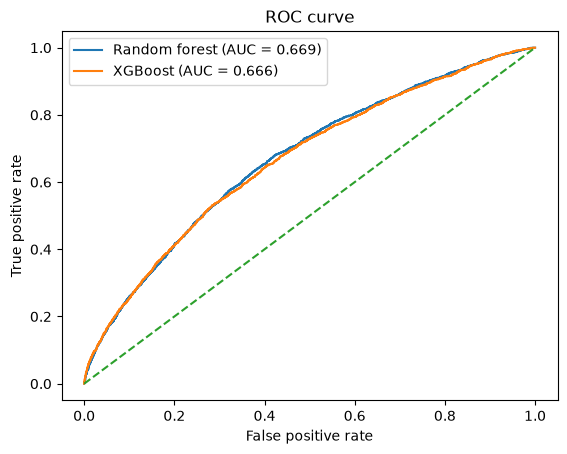

In [ ]:
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.savefig(FIGS / "tree_models_roc.png")
plt.show()

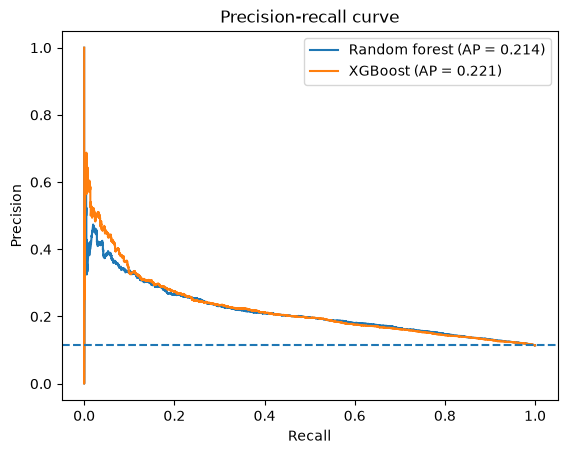

In [ ]:
for name, proba in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    plt.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, proba):.3f})")
plt.axhline(y_test.mean(), linestyle="--")  # random guessing
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve")
plt.legend()
plt.savefig(FIGS / "tree_models_pr.png")
plt.show()

## Prediction Importance

In [ ]:
imp = {}
for name, search in best.items():
    r = permutation_importance(search.best_estimator_, X_test, y_test,
                               scoring="average_precision", n_repeats=5,
                               random_state=SEED, n_jobs=-1)
    imp[name] = pd.Series(r.importances_mean, index=X_test.columns)

importance = pd.DataFrame(imp).sort_values("XGBoost", ascending=False).round(4)
importance.to_csv(FIGS / "tree_permutation_importance.csv")
importance.head(10)


,Random forest,XGBoost
number_inpatient,0.0455,0.0681
discharge_disposition,0.0356,0.0300
diag_1_group,0.0028,0.0052
medical_specialty,0.0046,0.0032
diag_2_group,0.0008,0.0030
payer_code,0.0017,0.0014
num_procedures,0.0004,0.0013
diag_3_group,0.0005,0.0012
number_diagnoses,0.0024,0.0012
time_in_hospital,0.0018,0.0010


In [ ]:
for name, proba in probas.items():
    tn, fp, fn, tp = confusion_matrix(y_test, (proba >= 0.5).astype(int)).ravel()
    print(f"{name}: flagged {tp+fp} ({(tp+fp)/len(y_test):.1%}), "
          f"found {tp}/{tp+fn}, accuracy {(tp+tn)/len(y_test):.3f}")


Random forest: flagged 5630 (28.3%), found 1113/2263, accuracy 0.715
XGBoost: flagged 7351 (37.0%), found 1314/2263, accuracy 0.648
